# House Prices — End-to-End Regression Project
## Project Overview
This project builds an end-to-end machine learning pipeline for the Kaggle House Prices: Advanced Regression Techniques competition.

The objective is to predict the final sale price of residential properties using a mixture of numerical and categorical features describing characteristics such as:

- Overall quality and condition,
- Living area,
- Basement and garage properties,
- Neighborhood,
- Construction and renovation dates,
- and other structural characteristics

The target variable is SalePrice, making this a supervised regression problem.

Rather than focusing only on obtaining a competitive Kaggle score, this project explores the complete tabular machine learning workflow:

- data inspection,
- missing value analysis,
- exploratory data analysis (EDA),
- feature engineering,
- leakage-safe preprocessing,
- model comparison,
- cross-validation,
- hyperparameter tuning,
- error analysis,
- feature importance,
- permutation importance,
- ablation studies,
- and final model training and submission.

The final model is selected based on validation performance measured primarily with RMSLE, which closely matches the evaluation objective of the competition

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    root_mean_squared_error,
    root_mean_squared_log_error,
)
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RandomizedSearchCV,
    cross_val_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [2]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

## Data Loading
The training and test datasets are loaded directly from the Kaggle competition input directory.
A custom missing-value parsing configuration is used:

```python
keep_default_na=False
na_values=["NA", ""]
```

This decision is important because some string values such as "None" represent legitimate categorical states in the datasets rather than missing information.

For example, "None" may indicate that a house does not contain a particular feature. Converting such values into NaN would incorrectly merge two different concepts:

- structural absence -> the feature does not exist,
- true missing information -> the value is unknown

Preserving this distinction becomes important during the missing-value analysis and preprocessing stages.

In [3]:

train_csv_path = "/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv"
test_csv_path = "/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv"

train_df = pd.read_csv(
    train_csv_path,
    keep_default_na=False,
    na_values=["NA", ""]
)

test_df = pd.read_csv(
    test_csv_path,
    keep_default_na=False,
    na_values=["NA", ""]
)

## Data Inspection

In [4]:
display(train_df.head())

train_df.info()

print(f"\nTrain df shape: {train_df.shape}")

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

---

## Missing Value Investigation
This part's main goal is to investigate the missing values and look if:

- Is information really missing?
- or NaN means this feature isn't available at home

In [5]:
missing_counts = train_df.isna().sum()
missing_counts = missing_counts[missing_counts > 0]
missing_counts.sort_values(ascending=False)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
FireplaceQu      690
LotFrontage      259
GarageCond        81
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
BsmtFinType2      38
BsmtExposure      38
BsmtCond          37
BsmtQual          37
BsmtFinType1      37
MasVnrType         8
MasVnrArea         8
Electrical         1
dtype: int64

In [6]:
poolqc_nans = train_df[train_df["PoolQC"].isna()]
print(train_df["PoolQC"].value_counts())

print("\n", poolqc_nans.shape)
print((poolqc_nans["PoolArea"] == 0).sum()) # the houses that has nan poolqc val has poolarea == 0

poolqc_not_nans = train_df[train_df["PoolQC"].notna()]
(poolqc_not_nans["PoolArea"] > 0).sum()

PoolQC
Gd    3
Ex    2
Fa    2
Name: count, dtype: int64

 (1453, 81)
1453


np.int64(7)

- PoolQC: 1453 missing values. All correspond to houses with PoolArea = 0. Likely represents the absence of a pool.
- Houses with not missing PoolQC vals have pool.

NaN is not unknown here, it's "No Pool". 
- Decision: fill them with "No Pool".

- GarageYrBlt: 81 Missing values. All correspond to houses with GarageArea = 0, and vice versa.
- and same thing goes on for the other categorical Garage columns.

The decision is: Treat these as structural missing values. Choose appropriate representations during preprocessing.

In [7]:
# Let's inspect the garage null values
mask_a = train_df["GarageYrBlt"].isna()
mask_b = train_df["GarageArea"] == 0

print((mask_a == mask_b).all())

garage_cols = [
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
]

mask_c = train_df[garage_cols].isna().all(axis=1)
# axis=1 performs operations across columns for each row.
# axis=0 performs operations down rows for each column.

print((mask_c == mask_b).all())

True
True


In [8]:
"""
Basement Features
We have BsmtQual 37 missing, BsmtCond 37 missing, BsmtFinType1 37 missing,
BsmtExposure 38 missing, BsmtFinType2 38 missing

Our hypothesis is: Are these values missing because there's no basement in the house?
"""
no_basement = train_df["TotalBsmtSF"] == 0

structural_basement_cols = [
    "BsmtQual",
    "BsmtCond",
    "BsmtFinType1",
]

structural_missing = (
    train_df[structural_basement_cols]
    .isna()
    .all(axis=1)
)

print("No basement houses:", no_basement.sum())
print("Exact match:", (no_basement == structural_missing).all())

No basement houses: 37
Exact match: True


Hypotesis confirmed.

In [9]:
for col in ["BsmtExposure", "BsmtFinType2"]:
    condition = (
        train_df[col].isna()
        & (train_df["TotalBsmtSF"] > 0)
    )

    display(
        train_df.loc[
            condition,
            [
                "Id",
                "TotalBsmtSF",
                "BsmtQual",
                "BsmtCond",
                "BsmtExposure",
                "BsmtFinType1",
                "BsmtFinType2",
                "BsmtFinSF2",
            ]
        ]
    )

,Id,TotalBsmtSF,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,BsmtFinSF2
948,949,936,Gd,TA,NaN,Unf,Unf,0


,Id,TotalBsmtSF,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,BsmtFinSF2
332,333,3206,Gd,TA,No,GLQ,NaN,479


37 houses have no basement, and the missing values in BsmtQual, BsmtCond and BsmtFinType1 correspond exactly to those houses. Therefore, there are structural missing values.
BsmtExposure (Id 949) and BsmtFintype2 (Id 333) each contain one additional missing observation in a house that actually has a basement, so those two cases are true missing values and should be handled separately during preprocessing.

### 1. Pool Features
- Finding: 1,453 missing PoolQC values correspond exactly to houses with PoolArea = 0.
- Decision: Represent missing PoolQC values as "No Pool" during preprocessing.

### 2. Garage Features
- Finding: 81 houses have GarageArea = 0. All five garage-related columns have missing values for these same houses.
- Decision: Use "No Garage" for missing categorical garage features. Handle GarageYrBlt separately as a numerical feature.

### 3. Basement Features
- Finding: 37 houses have no basement, explaining the structural missing values.
- Exceptions:
  - Id = 949: Missing BsmtExposure, despite having a basement.
  - Id = 333: Missing BsmtFinType2, despite having finished basement area.
- Decision: Use "No Basement" for structural missing values. Investigate appropriate imputation methods for the two exceptions.

Note: These are preliminary preprocessing decisions. No modifications have been applied to the original dataset.

In [10]:
"""
Fireplace Features
- Finding: All 690 missing FireplaceQu values correspond to
  houses with Fireplaces = 0

- Decision: Replace structural missing values with "No Fireplace" during
  preprocessing
"""
mask_a = train_df["FireplaceQu"].isna()
mask_b = train_df["Fireplaces"] == 0

print((mask_a == mask_b).all())

True


In [11]:
train_df["Alley"].value_counts(dropna=False)

Alley
NaN     1369
Grvl      50
Pave      41
Name: count, dtype: int64

### Alley Features
- Finding: 1,369 missing values. According to the data dictionary, NA represents no alley access.
- Decision: Replace structural missing values with "No Alley" during preprocessing.

In [12]:
train_df["Fence"].value_counts(dropna=False)

Fence
NaN      1179
MnPrv     157
GdPrv      59
GdWo       54
MnWw       11
Name: count, dtype: int64

### Fence Features
- Finding: 1,179 missing values. The data dictionary defines NA as "No Fence".
- Decision: Replace structural missing values with "No Fence" during preprocessing.

In [13]:
train_df["MiscFeature"].value_counts(dropna=False)

MiscFeature
NaN     1406
Shed      49
Gar2       2
Othr       2
TenC       1
Name: count, dtype: int64

### Miscellaneous Features
- Finding: 1,406 missing MiscFeature values. The data dictionary defines NA as "None".
- Decision: Replace structural missing values with "None" during preprocessing.

In [14]:
# Masonry veneer investigation
# `None` is a valid category (no masonry veneer), while `NA` is treated as missing.
print(train_df["MasVnrType"].value_counts(dropna=False))
print("\nMasVnrArea dtype:", train_df["MasVnrArea"].dtype)

masvnr_type_nans = train_df["MasVnrType"].isna()
train_df.loc[masvnr_type_nans, ["Id", "MasVnrType", "MasVnrArea"]]


MasVnrType
None       864
BrkFace    445
Stone      128
BrkCmn      15
NaN          8
Name: count, dtype: int64

MasVnrArea dtype: float64


,Id,MasVnrType,MasVnrArea
234,235,NaN,NaN
529,530,NaN,NaN
650,651,NaN,NaN
936,937,NaN,NaN
973,974,NaN,NaN
977,978,NaN,NaN
1243,1244,NaN,NaN
1278,1279,NaN,NaN


In [15]:
mask_type = train_df["MasVnrType"].isna()
mask_area = train_df["MasVnrArea"].isna()
print((mask_type == mask_area).all())


True


### Masonry Veneer Features
- **Finding:** `None` is a valid category meaning no masonry veneer. After correcting CSV parsing, only 8 houses have true missing values in both `MasVnrType` and `MasVnrArea`.
- **Decision:** Treat these 8 rows as true missing values and impute them separately during preprocessing.


In [16]:
# LotFrontage investigation
print(train_df["LotFrontage"].describe())

# Typical frontage differs by neighborhood
print(
    train_df.groupby("Neighborhood")["LotFrontage"]
    .median()
    .sort_values()
)

# Distribution of missing LotFrontage values across neighborhoods
print(
    train_df.loc[train_df["LotFrontage"].isna(), "Neighborhood"]
    .value_counts()
)


count    1201.000000
mean       70.049958
std        24.284752
min        21.000000
25%        59.000000
50%        69.000000
75%        80.000000
max       313.000000
Name: LotFrontage, dtype: float64
Neighborhood
BrDale     21.0
MeadowV    21.0
NPkVill    24.0
Blueste    24.0
Blmngtn    43.0
BrkSide    52.0
IDOTRR     60.0
OldTown    60.0
SWISU      60.0
StoneBr    61.5
Gilbert    65.0
Edwards    65.5
SawyerW    66.5
Veenker    68.0
CollgCr    70.0
Sawyer     71.0
NAmes      73.0
Mitchel    73.0
Somerst    73.5
Crawfor    74.0
ClearCr    80.0
NWAmes     80.0
Timber     85.0
NridgHt    88.5
NoRidge    91.0
Name: LotFrontage, dtype: float64
Neighborhood
NAmes      39
Gilbert    30
NWAmes     28
Sawyer     26
CollgCr    24
ClearCr    15
Mitchel    13
Crawfor    10
SawyerW     9
Edwards     8
Timber      8
Somerst     8
NoRidge     8
BrkSide     7
StoneBr     5
OldTown     4
Veenker     4
IDOTRR      3
Blmngtn     3
NPkVill     2
MeadowV     2
SWISU       2
NridgHt     1
Name: count, dty

### LotFrontage
- **Finding:** 259 values are missing and the missing observations are spread across many neighborhoods. Median frontage differs substantially between neighborhoods.
- **Decision:** A neighborhood-based imputation strategy was considered, but the final pipeline uses training-set median imputation for consistency and leakage safety.

In [17]:
# Electrical investigation
print(train_df["Electrical"].value_counts(dropna=False))
train_df.loc[train_df["Electrical"].isna(), ["Id", "Electrical"]]


Electrical
SBrkr    1334
FuseA      94
FuseF      27
FuseP       3
Mix         1
NaN         1
Name: count, dtype: int64


,Id,Electrical
1379,1380,NaN


### Electrical
- **Finding:** Only 1 value is missing. `SBrkr` is overwhelmingly the most common category (1334 / 1460).
- **Decision:** Decision: Treat as a true missing categorical value and let the categorical preprocessing pipeline impute it using the training-data mode.


### Missing Value Strategy

**Structural missing values**
- `PoolQC` → `"No Pool"`
- `MiscFeature` → `"None"`
- `Alley` → `"No Alley"`
- `Fence` → `"No Fence"`
- `FireplaceQu` → `"No Fireplace"`

**Garage**
- `GarageType`, `GarageFinish`, `GarageQual`, `GarageCond` → `"No Garage"`
- `GarageYrBlt` → handle separately as a numerical feature

**Basement**
- `BsmtQual`, `BsmtCond`, `BsmtFinType1` → `"No Basement"`
- `BsmtExposure`, `BsmtFinType2` → use `"No Basement"` only for structural missing rows; keep the true missing exceptions separate (`Id 949` and `Id 333`)

**True missing values**
- `MasVnrType` → 8 true missing values
- `MasVnrArea` → same 8 rows
- `Electrical` → Training-fitted most frequent imputation inside the categorical pipeline 

**Numerical imputation**
- `LotFrontage` → Training-fitted median imputation inside the numerical pipeline

**Important:** Structural absence and unknown/missing information are not the same thing.


In [18]:
# Re-check missing values after the corrected CSV parsing
missing_counts = train_df.isna().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)
print(missing_counts)
print("\nTotal missing values:", train_df.isna().sum().sum())


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
FireplaceQu      690
LotFrontage      259
GarageCond        81
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
BsmtFinType2      38
BsmtExposure      38
BsmtCond          37
BsmtQual          37
BsmtFinType1      37
MasVnrType         8
MasVnrArea         8
Electrical         1
dtype: int64

Total missing values: 6965


### Structural Missing Value Handling

In [19]:
structural_fill = {
    "PoolQC": "No Pool",
    "MiscFeature": "None",
    "Alley": "No Alley",
    "Fence": "No Fence",
    "FireplaceQu": "No Fireplace",
    "GarageType": "No Garage",
    "GarageFinish": "No Garage",
    "GarageQual": "No Garage",
    "GarageCond": "No Garage",
    "BsmtQual": "No Basement",
    "BsmtCond": "No Basement",
    "BsmtFinType1": "No Basement",
}

train_df = train_df.fillna(value=structural_fill)

print(train_df[list(structural_fill)].isna().sum())

PoolQC          0
MiscFeature     0
Alley           0
Fence           0
FireplaceQu     0
GarageType      0
GarageFinish    0
GarageQual      0
GarageCond      0
BsmtQual        0
BsmtCond        0
BsmtFinType1    0
dtype: int64


In [20]:
no_basement = train_df["TotalBsmtSF"] == 0

basement_cols = [
    "BsmtExposure",
    "BsmtFinType2",
]

train_df.loc[no_basement, basement_cols] = (
    train_df.loc[no_basement, basement_cols].fillna("No Basement")
)

train_df[basement_cols].isna().sum()

BsmtExposure    1
BsmtFinType2    1
dtype: int64

In [21]:
no_masvnr_type = train_df["MasVnrType"].isna()

train_df.loc[no_masvnr_type, [
    "Id", "MasVnrType", "MasVnrArea", "Neighborhood",
    "OverallQual", "YearBuilt", "Exterior1st", "Exterior2nd"]
]

# As we see, there's no such a strong pattern as we're looking for. So,
# leave these true missing values to the training-fitted preprocessing pipeline:
# MasVnrType -> most frequent imputation
# MasVnrArea -> median imputation

,Id,MasVnrType,MasVnrArea,Neighborhood,OverallQual,YearBuilt,Exterior1st,Exterior2nd
234,235,NaN,NaN,Gilbert,6,2002,VinylSd,VinylSd
529,530,NaN,NaN,Crawfor,6,1957,Wd Sdng,Stone
650,651,NaN,NaN,Somerst,7,2007,CemntBd,CmentBd
936,937,NaN,NaN,SawyerW,7,2003,VinylSd,VinylSd
973,974,NaN,NaN,Somerst,7,2007,CemntBd,CmentBd
977,978,NaN,NaN,Somerst,7,2006,VinylSd,VinylSd
1243,1244,NaN,NaN,NridgHt,10,2006,VinylSd,VinylSd
1278,1279,NaN,NaN,CollgCr,8,2002,VinylSd,VinylSd


---
## Target Variable Analysis

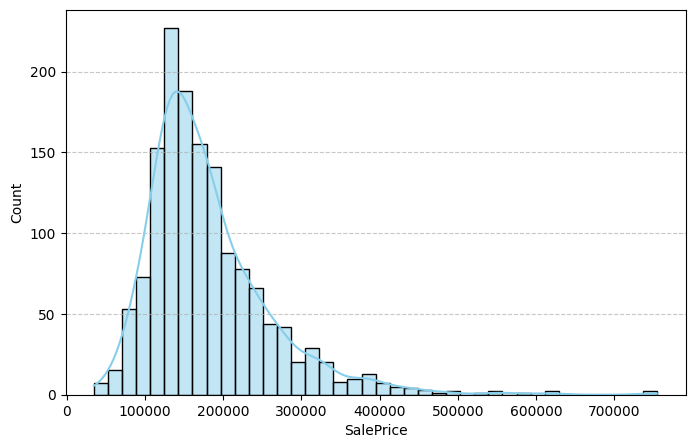

In [22]:
plt.figure(figsize=(8, 5))

sns.histplot(train_df["SalePrice"], bins=40, kde=True, color="skyblue", edgecolor="black")

plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

<Axes: xlabel='SalePrice'>

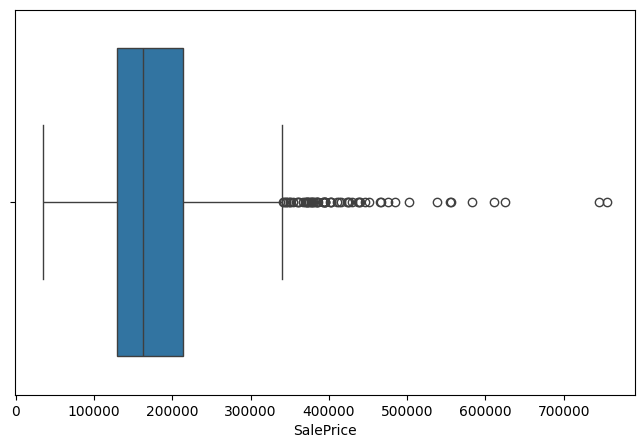

In [23]:
plt.figure(figsize=(8, 5))

sns.boxplot(x = train_df["SalePrice"])

In [24]:
print(train_df["SalePrice"].describe())
print("\nSkewness:", train_df["SalePrice"].skew())

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

Skewness: 1.8828757597682129


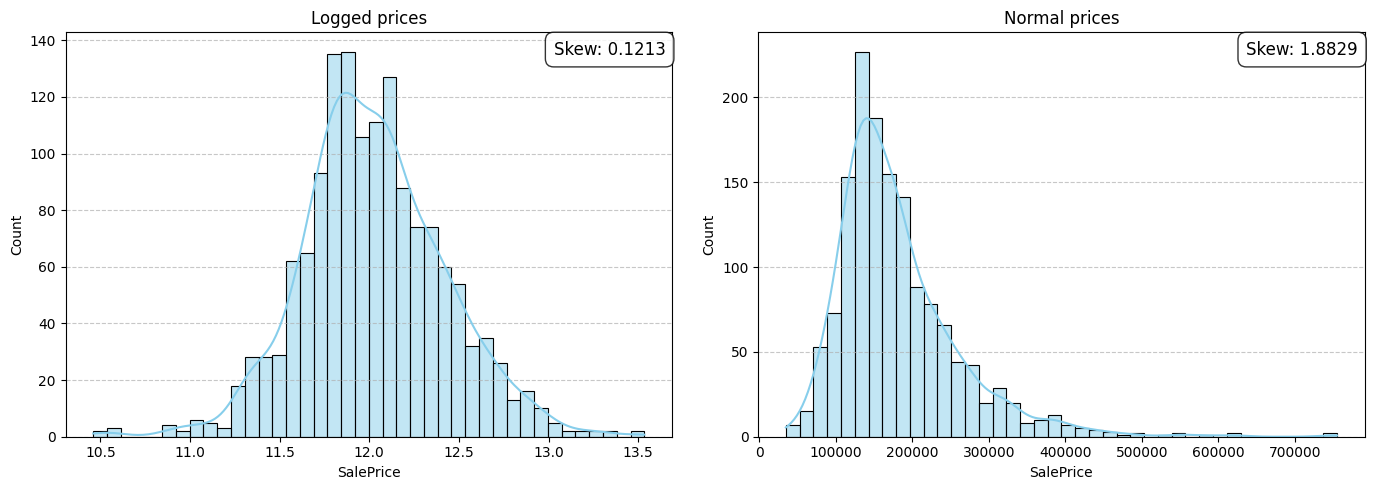

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --------------------- FIRST HISTOGRAM ------------------------- #
log_prices = np.log1p(train_df["SalePrice"])
sns.histplot(
    log_prices,
    ax=axes[0],
    bins=40,
    kde=True,
    color="skyblue",
    edgecolor="black"
)
# Skewness
axes[0].text(
    0.805,
    0.945,
    f"Skew: {log_prices.skew():.4f}",
    transform=axes[0].transAxes,
    fontsize=12,
    bbox=dict(
        boxstyle="round,pad=0.5", facecolor="white", alpha=0.8
    ),
)
axes[0].set_title("Logged prices")
# Grid
axes[0].grid(True, axis="y", linestyle="--", alpha=0.7)
# ----------------------- SECOND HISTOGRAM ------------------------ #
sns.histplot(
    train_df["SalePrice"],
    ax=axes[1],
    bins=40,
    kde=True,
    color="skyblue",
    edgecolor="black"
)
# Skewness
axes[1].text(
    0.805,
    0.945,
    f"Skew: {train_df["SalePrice"].skew():.4f}",
    transform=axes[1].transAxes,
    fontsize=12,
    bbox=dict(
        boxstyle="round,pad=0.5", facecolor="white", alpha=0.8
    ),
)
axes[1].set_title("Normal prices")
# Grid
axes[1].grid(True, axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()

*Target Distribution: SalePrice is strongly right-skewed (skewness = 1.8829), Applying log1p() reduces skewness to 0,1213, producing more symmetric distribution. We will evaluate whether this transformation improves model performance*

### Feature Relationships & Correlation

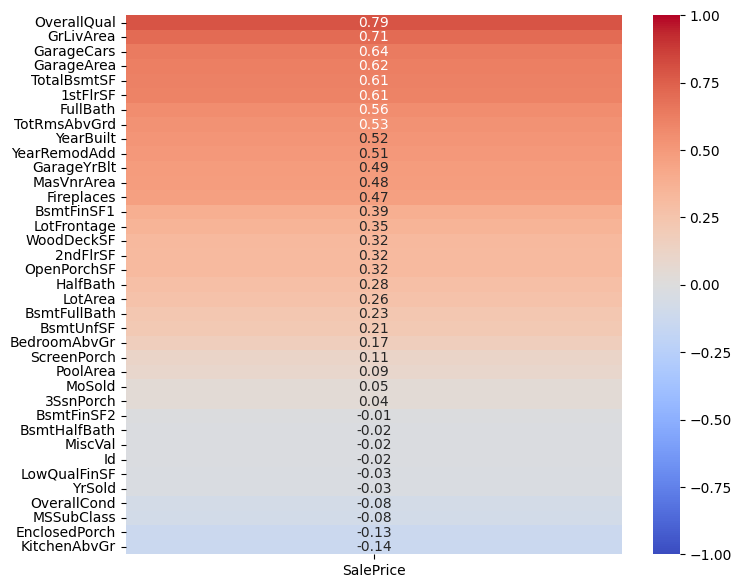

In [26]:
"""Numerical features and SalePrice"""
numerical_df = train_df.select_dtypes(include=["number"])
numerical_df_correlation = numerical_df.corr()

sale_price_correlation = (numerical_df_correlation[["SalePrice"]]
                        .sort_values(by="SalePrice", ascending=False)
                        .drop("SalePrice")
                         )
plt.figure(figsize=(8,7))

sns.heatmap(
    sale_price_correlation,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    fmt=".2f",
)
plt.show()

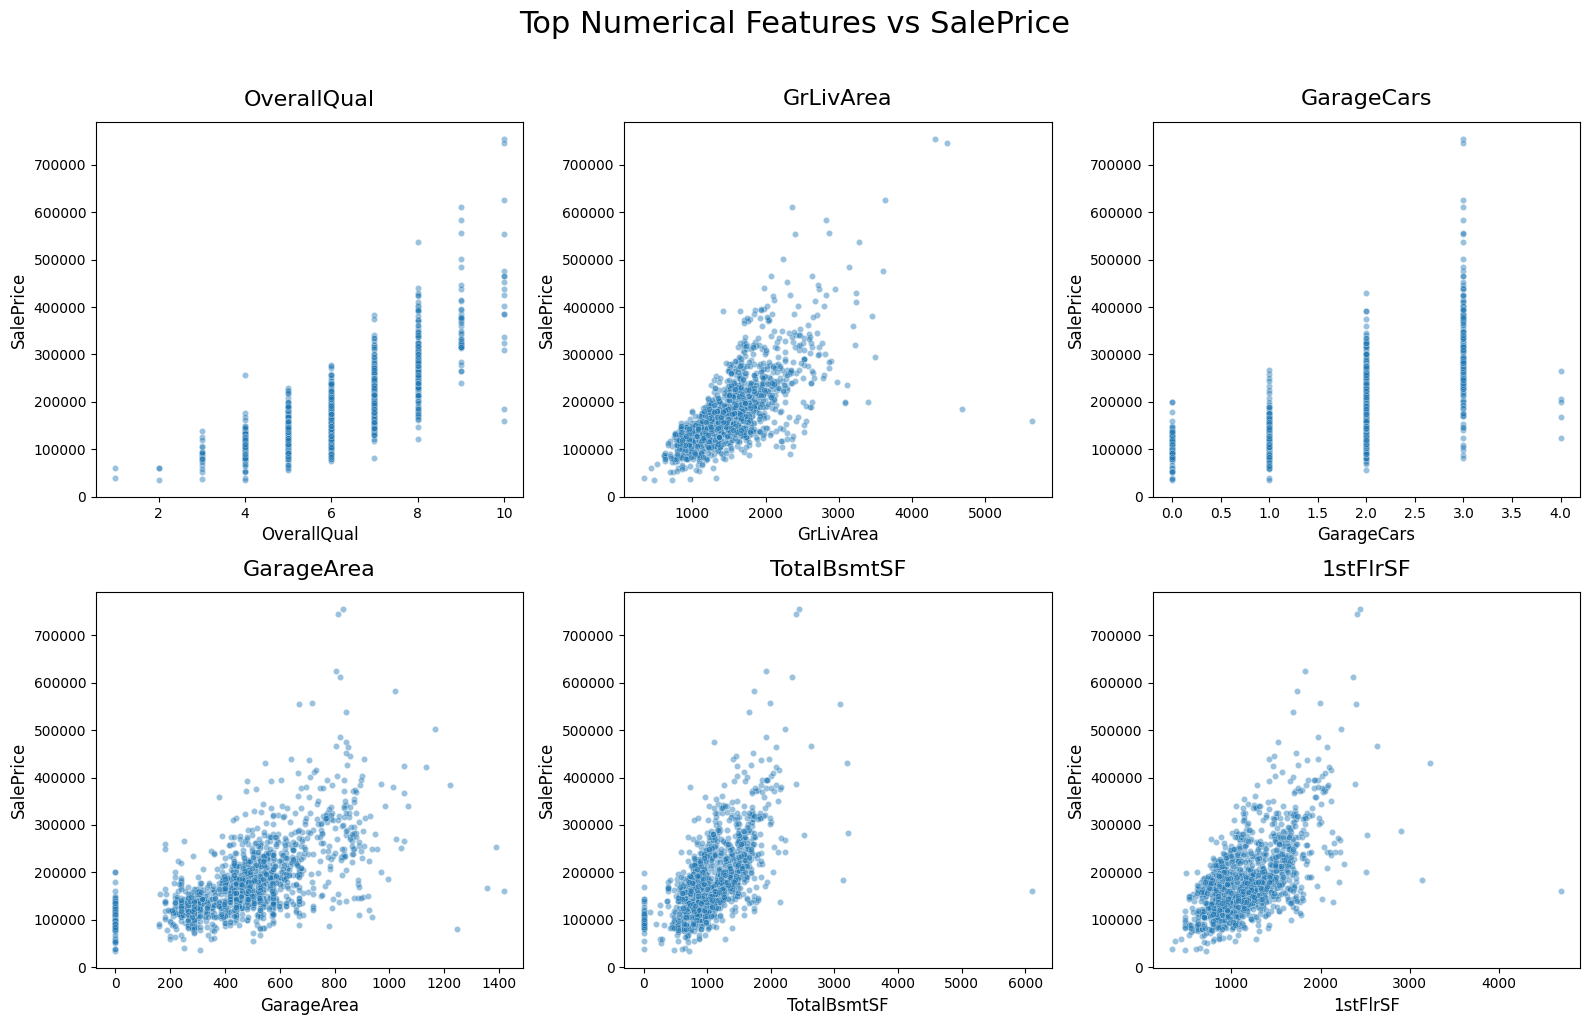

In [27]:
features = sale_price_correlation.index[:6]

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 10))

axes = axes.flatten()

for i, feature in enumerate(features):
    sns.scatterplot(
        x=train_df[feature],
        y=train_df["SalePrice"],
        ax=axes[i],
        alpha=0.45,
        s=20
    )
    axes[i].set_title(feature, fontsize=16, pad=12)
    axes[i].set_xlabel(feature, fontsize=12)
    axes[i].set_ylabel("SalePrice", fontsize=12)

plt.suptitle(
    "Top Numerical Features vs SalePrice",
    fontsize=22,
    y=1.02
)

plt.tight_layout()
plt.show()

In [28]:
condition = (train_df["GrLivArea"] > 4000) & (train_df["SalePrice"] < 300_000)


print(train_df.loc[condition, [
    "OverallQual", "OverallCond", "YearBuilt",
    "Neighborhood", "SaleCondition", "KitchenQual", "ExterQual"]
])

train_df.loc[condition, [
    "GrLivArea", "LotArea", "1stFlrSF", "2ndFlrSF", "TotalBsmtSF", "GarageArea"]
]

      OverallQual  OverallCond  YearBuilt Neighborhood SaleCondition  \
523            10            5       2007      Edwards       Partial   
1298           10            5       2008      Edwards       Partial   

     KitchenQual ExterQual  
523           Ex        Ex  
1298          Ex        Ex  


,GrLivArea,LotArea,1stFlrSF,2ndFlrSF,TotalBsmtSF,GarageArea
523,4676,40094,3138,1538,3138,884
1298,5642,63887,4692,950,6110,1418


Two houses with `GrLivArea` > 4000 have unusually low `SalePrice` values despite having very high quality ratings and recent construction years.

These observations are potential outliers, but they will not be removed yet. Their impact will be evaluated during model validation.

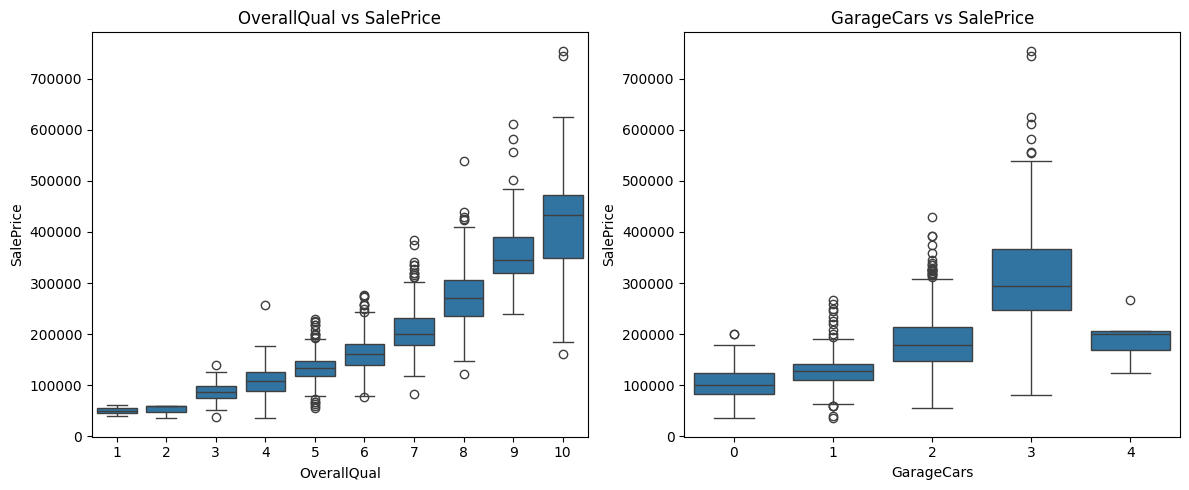

In [29]:
box_features = ["OverallQual", "GarageCars"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for i, feature in enumerate(box_features):
    sns.boxplot(
        x=train_df[feature],
        y=train_df["SalePrice"],
        ax=axes[i]
    )
    axes[i].set_title(f"{feature} vs SalePrice")

plt.tight_layout()
plt.show()

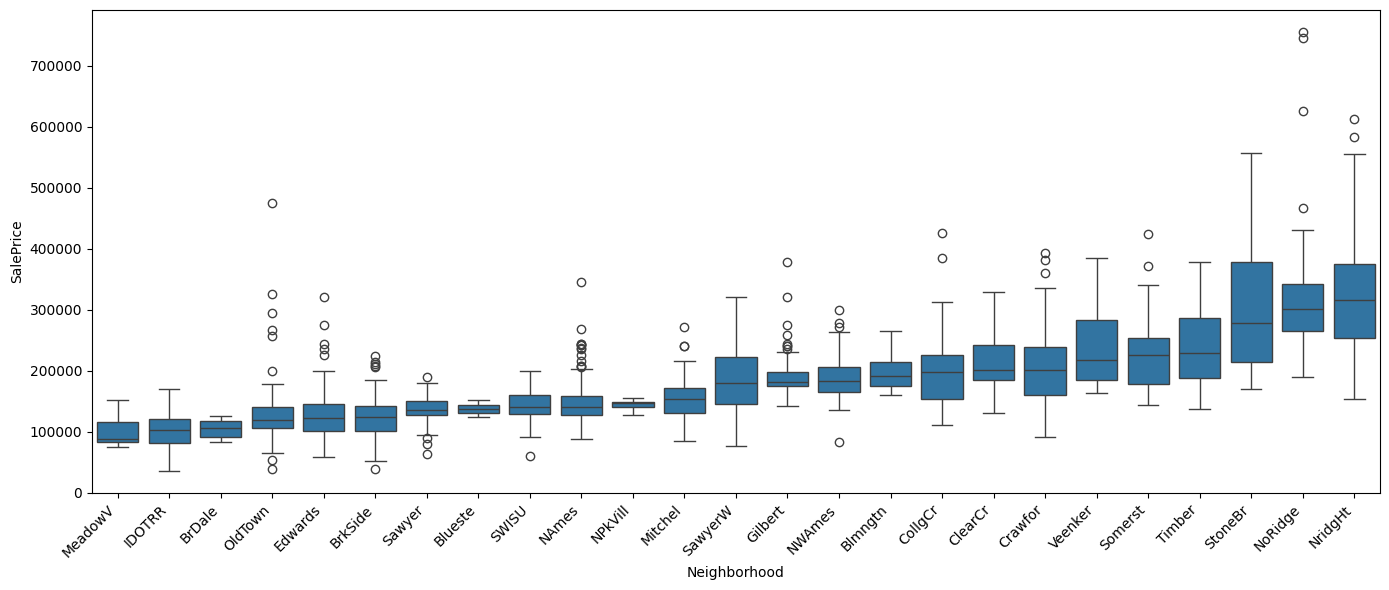

In [30]:
"""Categorical features and SalePrice"""

categorical_df = train_df.select_dtypes(include=["object"])

neighborhood_order = (
    train_df.groupby("Neighborhood")["SalePrice"]
    .median()
    .sort_values()
    .index
)

plt.figure(figsize=(14, 6))

sns.boxplot(
    x=train_df["Neighborhood"],
    y=train_df["SalePrice"],
    order=neighborhood_order,
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

House prices differ substantially across neighborhoods. Neighborhood is likely an important categorical predictor of SalePrice

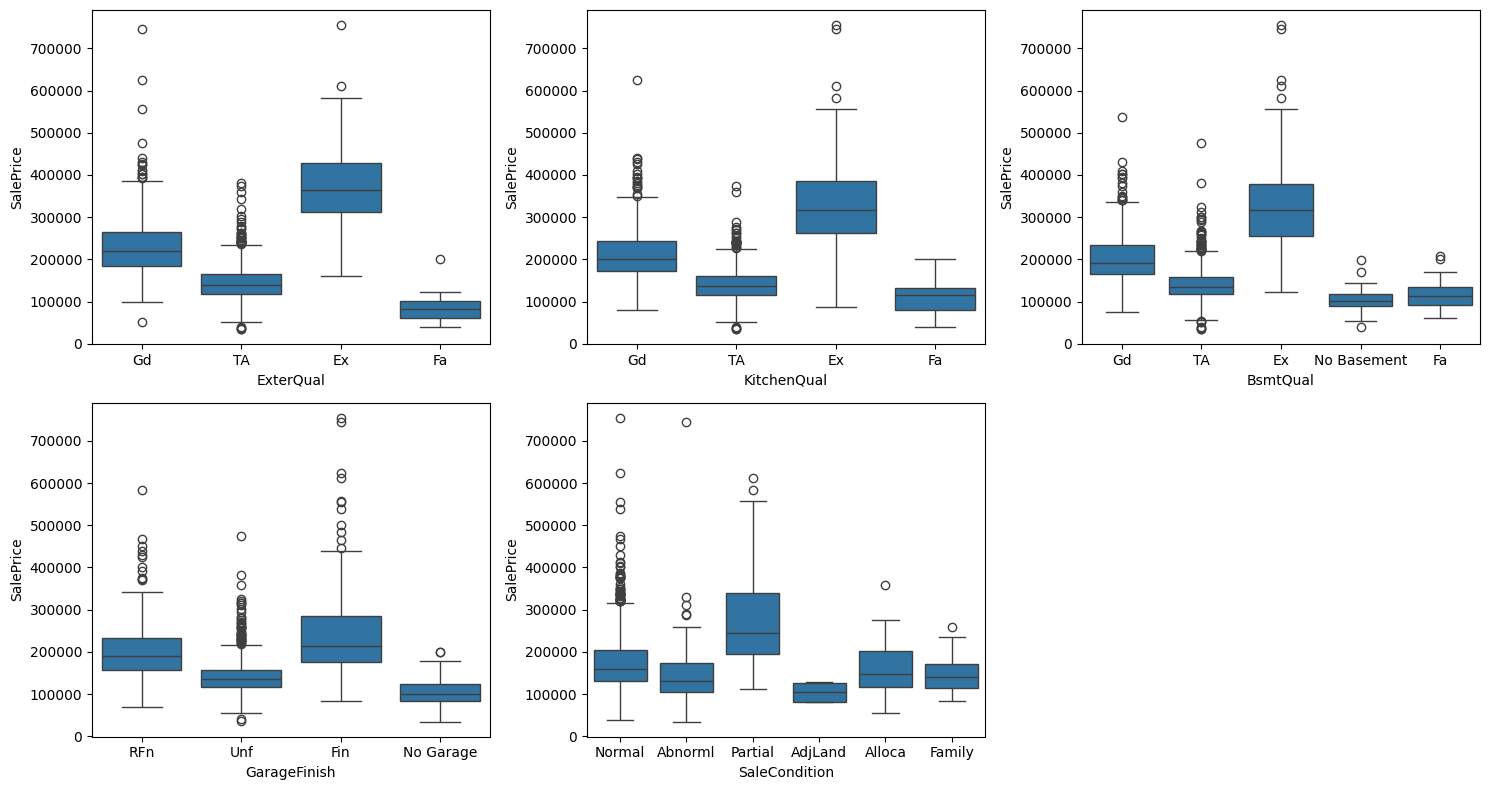

In [31]:
features = [
    "ExterQual",
    "KitchenQual",
    "BsmtQual",
    "GarageFinish",
    "SaleCondition",
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, feature in enumerate(features):
  sns.boxplot(
    x=train_df[feature],
    y=train_df["SalePrice"],
    ax=axes[i],
  )

axes[-1].axis("off")
plt.tight_layout()
plt.show()

## Feature Engineering

In [32]:
train_df["TotalSF"] = (
    train_df["TotalBsmtSF"] +
    train_df["1stFlrSF"] +
    train_df["2ndFlrSF"]
)

train_df[["TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "TotalSF"]].head()

,TotalBsmtSF,1stFlrSF,2ndFlrSF,TotalSF
0,856,856,854,2566
1,1262,1262,0,2524
2,920,920,866,2706
3,756,961,756,2473
4,1145,1145,1053,3343


In [33]:
total_sf_correlation = train_df["TotalSF"].corr(train_df["SalePrice"])
print(total_sf_correlation)

train_df["GrLivArea"].corr(train_df["SalePrice"])

# Does TotalSF, that I just created, carry a stronger linear relationship
# with SalePrice than GrLivArea? 

0.7822600527979846


np.float64(0.7086244776126523)

<Axes: xlabel='TotalSF', ylabel='SalePrice'>

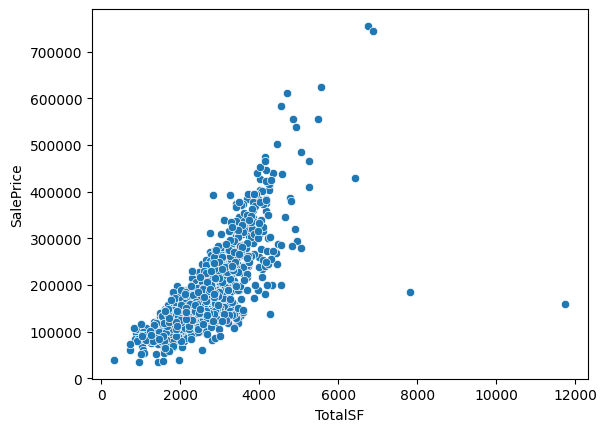

In [34]:
sns.scatterplot(x=train_df["TotalSF"], y=train_df["SalePrice"])

These two observations are unusually large relative to their sale prices. They are retained rather than removed based only on the target value, and their effect is left to model validation.

In [35]:
condition = (
    (train_df["GrLivArea"] > 4000) &
    (train_df["SalePrice"] < 300_000)
)

train_df.loc[
    condition,
    ["Id", "GrLivArea", "SalePrice", "OverallQual"]
]

,Id,GrLivArea,SalePrice,OverallQual
523,524,4676,184750,10
1298,1299,5642,160000,10


In [36]:
"""
GarageYrBlt has 81 missing values, and those 81 houses do not have a garage.
So I decided to do feature engineering for that and create a column, named: "HasGarage"
If house has a garage it's 1, otherwise 0.
"""

train_df["HasGarage"] = (train_df["GarageArea"] > 0).astype(int)
# (train_df["GarageArea"] > 0) first creates True, False boolean series,
# then we say .astype(int) which turns them into "1" and "0" True -> 1, False -> 0

train_df["GarageYrBlt"] = train_df["GarageYrBlt"].fillna(0)

print(train_df["HasGarage"].value_counts())
print(train_df["GarageYrBlt"].isna().sum())

HasGarage
1    1379
0      81
Name: count, dtype: int64
0


In [37]:
train_df["HouseAge"] = train_df["YrSold"] - train_df["YearBuilt"]

print((train_df["HouseAge"] < 0).sum())

print(train_df["HouseAge"].corr(train_df["SalePrice"]))

print(train_df["YearBuilt"].corr(train_df["SalePrice"]))

0
-0.523350417546816
0.5228973328794969


In [38]:
train_df["RemodAge"] = (
      train_df["YrSold"] - train_df["YearRemodAdd"]
).clip(lower=0)

print((train_df["RemodAge"] < 0).sum())

train_df["RemodAge"].corr(train_df["SalePrice"])

0


np.float64(-0.5090963444126457)

In [39]:
train_df["GarageAge"] = np.where(
    train_df["HasGarage"] == 1,
    train_df["YrSold"] - train_df["GarageYrBlt"],
    0
)

print((train_df["GarageAge"] < 0).sum())

print(train_df["GarageAge"].corr(train_df["SalePrice"]))

0
-0.3898082004901334


In [40]:
train_df["TotalBathrooms"] = (
    train_df["FullBath"]
    + train_df["BsmtFullBath"]
    + (0.5 * train_df["HalfBath"])
    + (0.5 * train_df["BsmtHalfBath"])
)

print((train_df["TotalBathrooms"] < 0).sum())

print(train_df["TotalBathrooms"].corr(train_df["SalePrice"]))

0
0.6317310679319873


### TRAIN / VALIDATION SPLIT

In [41]:
X = train_df.drop(columns=["Id", "SalePrice"])
y = train_df["SalePrice"]

# Since SalePrice is the target and Id is only an
# identifier so we can remove them.

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
# %80 training, %20 validation
# Defined a random_state so it's reproducible

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

X_train: (1168, 85)
X_val: (292, 85)
y_train: (1168,)
y_val: (292,)


### Preprocessing pipeline

In [42]:
numeric_cols = X_train.select_dtypes(
    include=["number"]).columns

categorical_cols = X_train.select_dtypes(
    include=["object"]).columns

"""Category Pipelines"""

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

"""
Column Transformer
It's going to decide which pipeline to apply for which columns
"""

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols),
])


In [43]:
"""Linear Regression"""
linear_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression()),
])

# Baseline: preprocessing + Linear Regression
linear_pipeline.fit(X_train, y_train)

y_pred = linear_pipeline.predict(X_val)

rmse = root_mean_squared_error(y_val, y_pred)
rmsle = root_mean_squared_log_error(y_val, y_pred)

print("RMSE:", rmse)
print("RMSLE:", rmsle)

RMSE: 30935.464704467195
RMSLE: 0.1719117154527475


In [44]:

numeric_pipeline_scaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor_scaled = ColumnTransformer([
    ("numeric", numeric_pipeline_scaled, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

linear_pipeline_scaled = Pipeline([
    ("preprocessor", preprocessor_scaled),
    ("model", LinearRegression())
])

In [45]:
y_train_log = np.log1p(y_train)

linear_pipeline_scaled.fit(X_train, y_train_log)

y_pred_log = linear_pipeline_scaled.predict(X_val)
y_pred_linear = np.expm1(y_pred_log)

rmse_log_target = root_mean_squared_error(
    y_val,
    y_pred_linear
)

rmsle_log_target = root_mean_squared_log_error(
    y_val,
    y_pred_linear
)

print("Log-target RMSE:", rmse_log_target)
print("Log-target RMSLE:", rmsle_log_target)

Log-target RMSE: 23550.560346746704
Log-target RMSLE: 0.14950798271911675


In [46]:
"""ElasticNet"""
elasticnet_pipeline = Pipeline([
    ("preprocessor", preprocessor_scaled),
    ("model", ElasticNet(max_iter=100000))
])

param_grid = {
    "model__alpha": [0.0001, 0.0003, 0.0005, 0.0007, 0.001, 0.0015],
    "model__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]
}

elasticnet_grid = GridSearchCV(
    estimator=elasticnet_pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1
)

elasticnet_grid.fit(X_train, y_train_log)

print("Best params:", elasticnet_grid.best_params_)
print("Best CV Log-RMSE:", -elasticnet_grid.best_score_)

Best params: {'model__alpha': 0.0015, 'model__l1_ratio': 0.7}
Best CV Log-RMSE: 0.1442781357575986


In [47]:
best_elasticnet = elasticnet_grid.best_estimator_

y_pred_elastic_log = best_elasticnet.predict(X_val)
y_pred_elastic = np.expm1(y_pred_elastic_log)

rmse_elastic = root_mean_squared_error(
    y_val,
    y_pred_elastic
)

rmsle_elastic = root_mean_squared_log_error(
    y_val,
    y_pred_elastic
)

print("Validation RMSE:", rmse_elastic)
print("Validation RMSLE:", rmsle_elastic)

Validation RMSE: 25522.63966882354
Validation RMSLE: 0.139143486741747


In [48]:
ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor_scaled),
    ("model", Ridge())
])

ridge_params = {
    "model__alpha": [0.1, 1, 3, 5, 10, 20, 50, 100]
}

ridge_grid = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_params,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1
)

ridge_grid.fit(X_train, y_train_log)

print("Best params:", ridge_grid.best_params_)
print("Best CV Log-RMSE:", -ridge_grid.best_score_)

Best params: {'model__alpha': 20}
Best CV Log-RMSE: 0.14471355166258926


In [49]:
best_ridge = ridge_grid.best_estimator_

y_pred_ridge_log = best_ridge.predict(X_val)
y_pred_ridge = np.expm1(y_pred_ridge_log)

rmse_ridge = root_mean_squared_error(y_val, y_pred_ridge)
rmsle_ridge = root_mean_squared_log_error(y_val, y_pred_ridge)

print("Validation RMSE:", rmse_ridge)
print("Validation RMSLE:", rmsle_ridge)

Validation RMSE: 25451.95148098429
Validation RMSLE: 0.13784845770339213


In [50]:
lasso_pipeline = Pipeline([
    ("preprocessor", preprocessor_scaled),
    ("model", Lasso(max_iter=100000))
])

lasso_params = {
    "model__alpha": [
        0.0001,
        0.0003,
        0.0005,
        0.0007,
        0.001,
        0.0015,
        0.002
    ]
}

lasso_grid = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_params,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1
)

lasso_grid.fit(X_train, y_train_log)

print("Best params:", lasso_grid.best_params_)
print("Best CV Log-RMSE:", -lasso_grid.best_score_)

Best params: {'model__alpha': 0.0007}
Best CV Log-RMSE: 0.14357425687000874


In [51]:
best_lasso = lasso_grid.best_estimator_

y_pred_lasso_log = best_lasso.predict(X_val)
y_pred_lasso = np.expm1(y_pred_lasso_log)

rmse_lasso = root_mean_squared_error(y_val, y_pred_lasso)
rmsle_lasso = root_mean_squared_log_error(y_val, y_pred_lasso)

print("Validation RMSE:", rmse_lasso)
print("Validation RMSLE:", rmsle_lasso)

Validation RMSE: 23555.62037981648
Validation RMSLE: 0.13471342283144871


In [52]:
"""Random Forest"""
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

rf_params = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [None, 15, 25],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2],
    "model__max_features": ["sqrt", 0.7]
}

rf_random = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_params,
    n_iter=8,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=0
)

rf_random.fit(X_train, y_train_log)

print("Best params:", rf_random.best_params_)
print("Best CV Log-RMSE:", -rf_random.best_score_)

Best params: {'model__n_estimators': 200, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 0.7, 'model__max_depth': 25}
Best CV Log-RMSE: 0.13832974006207718


In [53]:
best_rf = rf_random.best_estimator_

y_pred_rf_log = best_rf.predict(X_val)
y_pred_rf = np.expm1(y_pred_rf_log)

rmse_rf = root_mean_squared_error(y_val, y_pred_rf)
rmsle_rf = root_mean_squared_log_error(y_val, y_pred_rf)

print("Validation RMSE:", rmse_rf)
print("Validation RMSLE:", rmsle_rf)

Validation RMSE: 29510.386724573826
Validation RMSLE: 0.14353674823413937


We tested Random Forest as a non-linear tree ensemble baseline/candidate against linear models and explored reasonable hyperparameter combinations using randomized search; however, in terms of validation RMSLE, it underperformed compared to regularized linear models, and in particular, boosting methods.

In [54]:
"""XGBRegressor"""
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1
    ))
])

xgb_params = {
    "model__n_estimators": [300, 500, 800, 1200],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4, 5],
    "model__min_child_weight": [1, 3, 5],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__colsample_bytree": [0.7, 0.85, 1.0]
}

xgb_random = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_params,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=0
)

xgb_random.fit(X_train, y_train_log)

print("Best params:", xgb_random.best_params_)
print("Best CV Log-RMSE:", -xgb_random.best_score_)

Best params: {'model__subsample': 0.85, 'model__n_estimators': 800, 'model__min_child_weight': 5, 'model__max_depth': 3, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.85}
Best CV Log-RMSE: 0.12447375062281318


In [55]:
best_xgb_random = xgb_random.best_estimator_

y_pred_xgb_random_log = best_xgb_random.predict(X_val)
y_pred_xgb_random = np.expm1(y_pred_xgb_random_log)

rmse_xgb_random = root_mean_squared_error(
    y_val, 
    y_pred_xgb_random
)

rmsle_xgb_random = root_mean_squared_log_error(
    y_val, 
    y_pred_xgb_random
)

print("Validation RMSE:", rmse_xgb_random)
print("Validation RMSLE:", rmsle_xgb_random)

Validation RMSE: 25980.3671875
Validation RMSLE: 0.13217198848724365


In [56]:
xgb_grid_params = {
    "model__n_estimators": [700, 800, 900],
    "model__learning_rate": [0.04, 0.05, 0.06],
    "model__max_depth": [2, 3],
    "model__min_child_weight": [3, 5],
    "model__subsample": [0.8, 0.85],
    "model__colsample_bytree": [0.8, 0.85, 0.9],
}

xgb_grid = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=xgb_grid_params,
    scoring="neg_root_mean_squared_error",
    cv=3,
    n_jobs=-1,
    verbose=0
)

xgb_grid.fit(X_train, y_train_log)

print("Best params:", xgb_grid.best_params_)
print("Best CV Log-RMSE:", -xgb_grid.best_score_)

Best params: {'model__colsample_bytree': 0.85, 'model__learning_rate': 0.06, 'model__max_depth': 3, 'model__min_child_weight': 3, 'model__n_estimators': 700, 'model__subsample': 0.85}
Best CV Log-RMSE: 0.12330474970302892


In [57]:
final_xgb_params = {
    key.replace("model__", ""): value
    for key, value in xgb_grid.best_params_.items()
}

final_xgb_params

{'colsample_bytree': 0.85,
 'learning_rate': 0.06,
 'max_depth': 3,
 'min_child_weight': 3,
 'n_estimators': 700,
 'subsample': 0.85}

In [58]:
best_xgb = xgb_grid.best_estimator_

y_pred_xgb_log = best_xgb.predict(X_val)
y_pred_xgb = np.expm1(y_pred_xgb_log)

rmse_xgb = root_mean_squared_error(
    y_val,
    y_pred_xgb
)

rmsle_xgb = root_mean_squared_log_error(
    y_val,
    y_pred_xgb
)

print("Validation RMSE:", rmse_xgb)
print("Validation RMSLE:", rmsle_xgb)

Validation RMSE: 26024.048828125
Validation RMSLE: 0.12790542840957642


A promising hyperparameter region was identified using RandomizedSearch. This region was subsequently refined through a more focused GridSearch. The refined XGBoost model emerged as one of the strongest performers in terms of validation RMSLE.

In [59]:
import warnings

warnings.filterwarnings(
    "ignore",
    message="X does not have valid feature names, but LGBMRegressor was fitted with feature names"
)

In [60]:
"""LightGBM Regressor"""

lgbm_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LGBMRegressor(
        objective="regression",
        random_state=42,
        n_jobs=1,
        verbosity=-1,
        subsample_freq=1
    ))
])

lgbm_params = {
    "model__n_estimators": [300, 500, 800, 1200],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__num_leaves": [15, 31, 63],
    "model__max_depth": [2, 3, 4, 5],
    "model__min_child_samples": [10, 20, 30],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__colsample_bytree": [0.7, 0.85, 1.0]
}

lgbm_random = RandomizedSearchCV(
    estimator=lgbm_pipeline,
    param_distributions=lgbm_params,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=0
)

lgbm_random.fit(X_train, y_train_log)

print("Best params:", lgbm_random.best_params_)
print("Best CV Log-RMSE:", -lgbm_random.best_score_)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

Best params: {'model__subsample': 0.85, 'model__num_leaves': 63, 'model__n_estimators': 1200, 'model__min_child_samples': 10, 'model__max_depth': 2, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.7}
Best CV Log-RMSE: 0.12232801757884404


In [61]:
best_lgbm = lgbm_random.best_estimator_

y_pred_lgbm_log = best_lgbm.predict(X_val)
y_pred_lgbm = np.expm1(y_pred_lgbm_log)

rmse_lgbm = root_mean_squared_error(y_val, y_pred_lgbm)
rmsle_lgbm = root_mean_squared_log_error(y_val, y_pred_lgbm)

print("Validation RMSE:", rmse_lgbm)
print("Validation RMSLE:", rmsle_lgbm)

Validation RMSE: 28581.161186027988
Validation RMSLE: 0.1326647713952801


In [62]:
# We gotta fill the missing features for CatBoost
X_train_cat = X_train.copy()
X_val_cat = X_val.copy()

cat_features = list(categorical_cols)
num_features = list(numeric_cols)

# categorical NaN -> string category
for col in cat_features:
  X_train_cat[col] = X_train_cat[col].fillna("Missing").astype(str)
  X_val_cat[col] = X_val_cat[col].fillna("Missing").astype(str)

# numeric NaN -> median learned ONLY from train
for col in num_features:
  median_value = X_train_cat[col].median()

  X_train_cat[col] = X_train_cat[col].fillna(median_value)
  X_val_cat[col] = X_val_cat[col].fillna(median_value)

Since CatBoost can process the categorical variables natively, we didn't use one-hot encoding. And because CatBoost doesn't accept categorical NaN's, we turned them into "Missing" category. Numeric missing values got filled with training set's median.

In [63]:
catboost_model = CatBoostRegressor(
    loss_function="RMSE",
    random_seed=42,
    verbose=0
)

cat_features = list(categorical_cols)

catboost_model.fit(
    X_train_cat,
    y_train_log,
    cat_features=cat_features,
)

CatBoostRegressor(loss_function='RMSE', random_seed=42, verbose=0)

In [64]:
y_pred_cat_log = catboost_model.predict(X_val_cat)
y_pred_cat = np.expm1(y_pred_cat_log)

rmse_cat = root_mean_squared_error(
    y_val, 
    y_pred_cat
)

rmsle_cat = root_mean_squared_log_error(
    y_val,
    y_pred_cat
)

print("CatBoost RMSE:", rmse_cat)
print("CatBoost RMSLE:", rmsle_cat)

CatBoost RMSE: 27463.875628195095
CatBoost RMSLE: 0.1285832318641582


## Model Comparison
Models are compared using the same validation split, and RMSLE is used as the primary selection metric.

In [65]:
results = {
    "Model": [
        "Ridge",
        "Lasso",
        "ElasticNet",
        "Random Forest",
        "XGBoost",
        "LightGBM",
        "CatBoost"
    ],
    "Validation RMSLE": [
        rmsle_ridge,
        rmsle_lasso,
        rmsle_elastic,
        rmsle_rf,
        rmsle_xgb,
        rmsle_lgbm,
        rmsle_cat,
    ],
}

results_df = (
    pd.DataFrame(results)
    .sort_values("Validation RMSLE")
    .reset_index(drop=True)
)

results_df

,Model,Validation RMSLE
0,XGBoost,0.127905
1,CatBoost,0.128583
2,LightGBM,0.132665
3,Lasso,0.134713
4,Ridge,0.137848
5,ElasticNet,0.139143
6,Random Forest,0.143537


- The lower the RMSLE, the better
- XGBoost has the best validation score
- Lasso and ElasticNet has surprisingly good scores
- CatBoost and LightGBM are good but, they lag behind XGBoost
- RandomForest is noticeably weak

So we selected XGBoost as main model for error analysis.

## Error Analysis

In [66]:
error_df = X_val.copy()

error_df["ActualPrice"] = y_val
error_df["PredictedPrice"] = y_pred_xgb

error_df["LogError"] = (
    np.log1p(error_df["ActualPrice"]) -
    np.log1p(error_df["PredictedPrice"])
).abs()

error_df["Residual"] = (
    error_df["ActualPrice"]
    - error_df["PredictedPrice"]
)

error_df.sort_values(
    "LogError", 
    ascending=False
)[
    [
        "ActualPrice",
        "PredictedPrice", 
        "LogError", 
        "OverallQual",
        "GrLivArea",
        "YearBuilt",
        "Neighborhood"
    ]
].head(10)

,ActualPrice,PredictedPrice,LogError,OverallQual,GrLivArea,YearBuilt,Neighborhood
30,40000,90988.289062,0.821837,4,1317,1920,IDOTRR
916,35311,64769.878906,0.606633,2,480,1949,IDOTRR
1432,64500,106794.843750,0.504238,4,968,1927,OldTown
588,143000,226714.328125,0.460844,5,1473,1968,ClearCr
812,55993,85365.062500,0.421704,5,1044,1952,IDOTRR
581,253293,376621.937500,0.396694,8,2042,2008,NridgHt
774,395000,269879.468750,0.380909,8,1973,2006,NridgHt
628,135000,184798.640625,0.313990,5,2080,1969,NAmes
607,225000,164797.343750,0.311382,5,2008,1948,Edwards
218,311500,228670.578125,0.309116,7,1954,1939,Crawfor


In [67]:
error_df["PriceGroup"] = pd.qcut(
    error_df["ActualPrice"],
    q=4,
    labels=["Low", "Mid-Low", "Mid-High", "High"]
)

error_df.groupby(
    "PriceGroup",
    observed=True
).agg(
    Count=("ActualPrice", "size"),
    MeanActual=("ActualPrice", "mean"),
    MeanPredicted=("PredictedPrice", "mean"),
    MeanResidual=("Residual", "mean"),
    MeanLogError=("LogError", "mean")
)

,Count,MeanActual,MeanPredicted,MeanResidual,MeanLogError
PriceGroup,,,,,
Low,75,101607.413333,106317.632812,-4710.220677,0.106468
Mid-Low,71,139672.633803,138662.078125,1010.550176,0.075615
Mid-High,73,179376.356164,180095.796875,-719.444135,0.060369
High,73,295745.726027,285531.562500,10214.152183,0.095710


Low -> negative residual
Mid -> lower error
High -> positive residual

Since our residual definition is: Actual - Predicted

- negative residual ->  model overpredict
- positive residual -> model underpredict

So model pulling edges to the center

- cheap houses -> little overpredict
- expensive houses -> little underpredict

That's classical regression-to-the-mean behavior.

### Conclusion
- worst relative errors mostly appear among unusual low-price houses
- middle price ranges are predicted more accurately
- low-price homes tend to be overpredicted
- high-price homes tend to be underpredicted
- this suggests regression toward the mean

No new feature decisions were made solely from the holdout analysis

## Feature Importance

In [68]:
xgb_model = best_xgb.named_steps["model"]
xgb_preprocessor = best_xgb.named_steps["preprocessor"]

feature_names = xgb_preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

importance_df.head(20)

,Feature,Importance
3,numeric__OverallQual,0.125719
36,numeric__TotalSF,0.108067
237,categorical__KitchenQual_TA,0.062910
188,categorical__BsmtQual_Ex,0.048782
228,categorical__CentralAir_N,0.047940
273,categorical__GarageCond_TA,0.045287
25,numeric__GarageCars,0.044258
41,numeric__TotalBathrooms,0.029250
46,categorical__MSZoning_RM,0.025852
21,numeric__KitchenAbvGr,0.024773


`TotalSF`, `OverallQual`, `GarageCars`, and several quality/category features rank highly.

**Critical note**:
XGBoost feature importance does not mean that a feature explains %13 of the house price. It is a model-specific metric that reflects how much the feature contributed to tree splits. 

In [69]:
perm_result = permutation_importance(
    best_xgb,
    X_val,
    np.log1p(y_val),
    scoring="neg_root_mean_squared_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

perm_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
}).sort_values(
    "Importance",
    ascending=False
)

perm_df.head(20)

# Shuffle one feature at a time, and measure how much validation performance degrades

# Larger positive permutation importance = model performance worsens more when 
# that feature is shuffled

,Feature,Importance,Std
79,TotalSF,0.125883,0.004596
16,OverallQual,0.062485,0.002529
84,TotalBathrooms,0.012746,0.001167
17,OverallCond,0.012185,0.001644
45,GrLivArea,0.007492,0.001252
3,LotArea,0.007154,0.001377
81,HouseAge,0.005873,0.000730
82,RemodAge,0.005453,0.001218
1,MSZoning,0.004789,0.000406
55,Fireplaces,0.004760,0.001655


XGBoost built-in importance and permutation importance do not measure the same thing.

- Built-in: To what extent did the model tree's use the feature?
- Permutation: How much does validation performance deteriorate when the feature's information is randomly disrupted.

In [70]:
engineered_features = [
    "TotalSF",
    "HouseAge",
    "RemodAge",
    "GarageAge",
    "TotalBathrooms"
]

tuned_xgb_params = {
    key.replace("model__", ""): value
    for key, value in xgb_grid.best_params_.items()
}

ablation_results = {}

# Full feature set
full_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1,
        **tuned_xgb_params
    ))
])

full_scores = cross_val_score(
    full_model,
    X_train,
    y_train_log,
    scoring="neg_root_mean_squared_error",
    cv=3,
    n_jobs=-1
)

ablation_results["All features"] = -full_scores.mean()

# Remove engineered features one by one
for feature in engineered_features:
    X_train_ablation = X_train.drop(columns=[feature])

    xgb_ablation = Pipeline([
        ("preprocessor", ColumnTransformer([
            (
                "numeric",
                numeric_pipeline,
                X_train_ablation.select_dtypes(
                    include=["number"]
                ).columns
            ),
            (
                "categorical",
                categorical_pipeline,
                X_train_ablation.select_dtypes(
                    include=["object"]
                ).columns
            )
        ])),
        ("model", XGBRegressor(
            objective="reg:squarederror",
            random_state=42,
            n_jobs=1,
            **tuned_xgb_params
        ))
    ])

    scores = cross_val_score(
        xgb_ablation,
        X_train_ablation,
        y_train_log,
        scoring="neg_root_mean_squared_error",
        cv=3,
        n_jobs=-1
    )

    ablation_results[f"Without {feature}"] = -scores.mean()

pd.Series(ablation_results).sort_values()

All features              0.123305
Without GarageAge         0.123666
Without RemodAge          0.124262
Without HouseAge          0.124512
Without TotalSF           0.125534
Without TotalBathrooms    0.125550
dtype: float64

Feature importance: How much does the model use the feature?
Ablation: Does model performance really change when the feature is removed

- `All features` performs the best.
- When any engineered feature is taken out, CV Log-RMSE increases.
- Biggest degradation happens when `TotalBathrooms` and `TotalSF` are removed.
- `GarageAge` has some contribution, but its marginal effect is less than others.

Small score differences may partly reflect CV variance, but all five engineered features worsened performance when removed, so there is consistent evidence that they are useful.

## Final Training Pipeline

### Reusable Feature Preparation

In [71]:
"""
We bring together all of the deterministic preprocessing and feature engineering
decisions that we explored before in one reusable function.
"""

def prepare_features(df):
  df = df.copy()

  structural_fill = {
      "PoolQC": "No Pool",
      "MiscFeature": "None",
      "Alley": "No Alley",
      "Fence": "No Fence",
      "FireplaceQu": "No Fireplace",
      "GarageType": "No Garage",
      "GarageFinish": "No Garage",
      "GarageQual": "No Garage",
      "GarageCond": "No Garage",
      "BsmtQual": "No Basement",
      "BsmtCond": "No Basement",
      "BsmtFinType1": "No Basement",
  }

  df = df.fillna(value=structural_fill)

  no_basement = df["TotalBsmtSF"] == 0

  df.loc[no_basement, ["BsmtExposure", "BsmtFinType2"]] = (
      df.loc[no_basement, ["BsmtExposure", "BsmtFinType2"]]
      .fillna("No Basement")
  )

  df["HasGarage"] = (df["GarageArea"] > 0).astype(int)

  df["GarageYrBlt"] = df["GarageYrBlt"].fillna(0)

  df["TotalSF"] = (
      df["TotalBsmtSF"]
      + df["1stFlrSF"]
      + df["2ndFlrSF"]
  )

  df["HouseAge"] = df["YrSold"] - df["YearBuilt"]

  df["RemodAge"] = (
      df["YrSold"] - df["YearRemodAdd"]
  ).clip(lower=0)

  df["GarageAge"] = np.where(
      df["HasGarage"] == 1,
      df["YrSold"] - df["GarageYrBlt"],
      0
  )

  df["TotalBathrooms"] = (
      df["FullBath"]
      + df["BsmtFullBath"]
      + 0.5 * df["HalfBath"]
      + 0.5 * df["BsmtHalfBath"]
  )

  return df

### Load Fresh Training and Test Data

In [72]:
train_final = pd.read_csv(
    train_csv_path,
    keep_default_na=False,
    na_values=["NA", ""]
)


test_final = pd.read_csv(
    test_csv_path,
    keep_default_na=False,
    na_values=["NA", ""]
)

train_final = prepare_features(train_final)
test_final = prepare_features(test_final)

### Final Preprocessing and Model

In [73]:
test_ids = test_final["Id"].copy()

X_final = train_final.drop(columns=["Id", "SalePrice"])
y_final = np.log1p(train_final["SalePrice"])

X_test_final = test_final.drop(columns=["Id"])

final_numeric_cols = X_final.select_dtypes(include=["number"]).columns
final_categorical_cols = X_final.select_dtypes(include=["object"]).columns

In [74]:
final_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])

final_categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

final_preprocessor = ColumnTransformer([
    ("numeric", final_numeric_pipeline, final_numeric_cols),
    ("categorical", final_categorical_pipeline, final_categorical_cols)
])

### Train on Full Training Set

In [75]:
final_model = Pipeline([
    ("preprocessor", final_preprocessor),
    ("model", XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1,
        **final_xgb_params
    ))
])

final_model.fit(X_final, y_final)

test_pred_log = final_model.predict(X_test_final)
test_pred = np.expm1(test_pred_log)

### Submission

In [76]:
submission = pd.DataFrame({
    "Id": test_ids,
    "SalePrice": test_pred
})

submission.to_csv("submission.csv", index=False)

submission.head()

,Id,SalePrice
0,1461,122907.375000
1,1462,160477.187500
2,1463,183051.093750
3,1464,197178.312500
4,1465,189820.796875


## Conclusion
- We solved a supervised tabular regression problem in this project by predicting `SalePrice`.
- Used log-target instead of raw target, because `SalePrice` was strongly right-skewed. And `log1p` significantly reduced the skewness.
- The strongest models included Lasso, ElasticNet, CatBoost, LightGBM and XGBoost, with XGBoost achieving the best validation RMSLE and being selected as the final model.
- We validated the usefulness of the engineered features through an ablation study.
- We built a leakage-safe and reusable preprocessing -> training -> inference workflow.